# 01 - Preliminary profiling: OWID CO2 data + World Bank indicators

**Purpose.** This notebook is the evidence base for the Week 1 EDA *proposal*. It does not answer the research questions; it checks that the two chosen datasets can be downloaded, understood and joined, and it records the data-quality issues that the cleaning plan must handle.

Every number shown here is computed by `src/profile_data.py`; nothing is typed in by hand. Run all cells top to bottom (the first run downloads about 21 MB).

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import profile_data as pdx

pd.set_option("display.max_columns", 30, "display.width", 140, "display.float_format", "{:,.2f}".format)
S = pdx.main(refresh=False)          # downloads if raw files are missing, then profiles
o, w, j = S["owid"], S["worldbank"], S["join"]
print("Profiling finished. Tables are in data/processed/profiling/, figures in figures/")

Profiling finished. Tables are in data/processed/profiling/, figures in figures/


## 1. OWID CO2 dataset: structure

In [2]:
owid = pd.read_csv(ROOT / "data/raw/owid-co2-data.csv")
print("shape:", owid.shape, "| years:", owid.year.min(), "-", owid.year.max(), "| entities:", owid.country.nunique())
print("dtype counts:", owid.dtypes.astype(str).value_counts().to_dict())
print("duplicate (country, year) rows:", owid.duplicated(["country", "year"]).sum())
owid[["country", "year", "iso_code", "population", "gdp", "co2", "co2_per_capita", "primary_energy_consumption"]].sample(6, random_state=1)

shape: (50411, 79) | years: 1750 - 2024 | entities: 254
dtype counts: {'float64': 76, 'str': 2, 'int64': 1}
duplicate (country, year) rows: 0


,country,year,iso_code,population,gdp,co2,co2_per_capita,primary_energy_consumption
3759,Austria,1898,AUT,"5,858,271.00","26,650,656,000.00",24.45,4.17,NaN
34265,North America (excl. USA),2004,NaN,NaN,NaN,"1,158.28",5.50,NaN
31934,Nepal,1997,NPL,"23,219,458.00","34,660,347,793.00",2.64,0.11,8.26
7606,Brunei,1968,BRN,"126,237.00",NaN,0.43,3.40,NaN
3490,Australia,1836,AUS,"381,599.00","658,031,000.00",0.02,0.05,NaN
40755,Seychelles,1965,SYC,"48,295.00","160,848,000.00",0.01,0.15,NaN


**Reading.** One row per entity-year, 79 columns, no duplicate keys. The `str` dtype is how pandas 3 labels text columns. Before trusting any aggregate, check which "countries" are really countries.

In [3]:
ent = pd.read_csv(ROOT / "data/processed/profiling/owid_non_country_entities.csv")
print(f"{o['n_non_country_entities']} entities have no ISO code = {o['pct_rows_non_country']}% of all rows")
ent

36 entities have no ISO code = 15.73% of all rows


,country,rows,first,last,iso
0,Africa,275,1750,2024,NaN
1,Africa (GCP),175,1850,2024,NaN
2,Asia,275,1750,2024,NaN
3,Asia (GCP),175,1850,2024,NaN
4,Asia (excl. China and India),275,1750,2024,NaN
5,Central America (GCP),175,1850,2024,NaN
6,Europe,275,1750,2024,NaN
7,Europe (GCP),175,1850,2024,NaN
8,Europe (excl. EU-27),275,1750,2024,NaN
9,Europe (excl. EU-28),275,1750,2024,NaN


**Reading.** Regions (Africa, Europe), income groups, `World`, `International aviation/shipping` and the odd territory (`Kosovo`, `Ryukyu Islands`) carry no ISO code. Summing them with countries would double count, so the cleaning plan routes them into a separate aggregates table.

## 2. OWID: missing values and coverage

In [4]:
mt = pd.read_csv(ROOT / "data/processed/profiling/owid_missing_by_column.csv", index_col=0)
print(f"{o['n_cols_over_50pct_missing']} of {o['shape'][1]} columns are more than 50% missing; median column is {o['median_pct_missing_across_cols']}% missing")
mt.head(12)

45 of 79 columns are more than 50% missing; median column is 52.8% missing


,dtype,n_missing,pct_missing,n_unique
share_global_cumulative_other_co2,float64,48241,95.70,1172
share_global_other_co2,float64,48241,95.70,1267
other_co2_per_capita,float64,47752,94.73,317
cumulative_other_co2,float64,47157,93.55,2136
other_industry_co2,float64,47157,93.55,1748
consumption_co2_per_gdp,float64,45963,91.18,847
consumption_co2_per_capita,float64,45768,90.79,3811
trade_co2,float64,45699,90.65,4328
trade_co2_share,float64,45699,90.65,4453
consumption_co2,float64,45358,89.98,4929


In [5]:
rows = pd.DataFrame({
    "metric": ["CO2 (total)", "CO2 per capita", "Population", "GDP (OWID)"],
    "% missing, 1990-2022, countries only": [o["window_co2_pct_missing"], o["window_co2_pc_pct_missing"],
                                             o["window_pop_pct_missing"], o["window_gdp_pct_missing"]]})
print("Study window rows (218 countries x 33 years):", o["window_rows"])
rows

Study window rows (218 countries x 33 years): 7194


,metric,"% missing, 1990-2022, countries only"
0,CO2 (total),1.61
1,CO2 per capita,2.47
2,Population,0.92
3,GDP (OWID),24.80


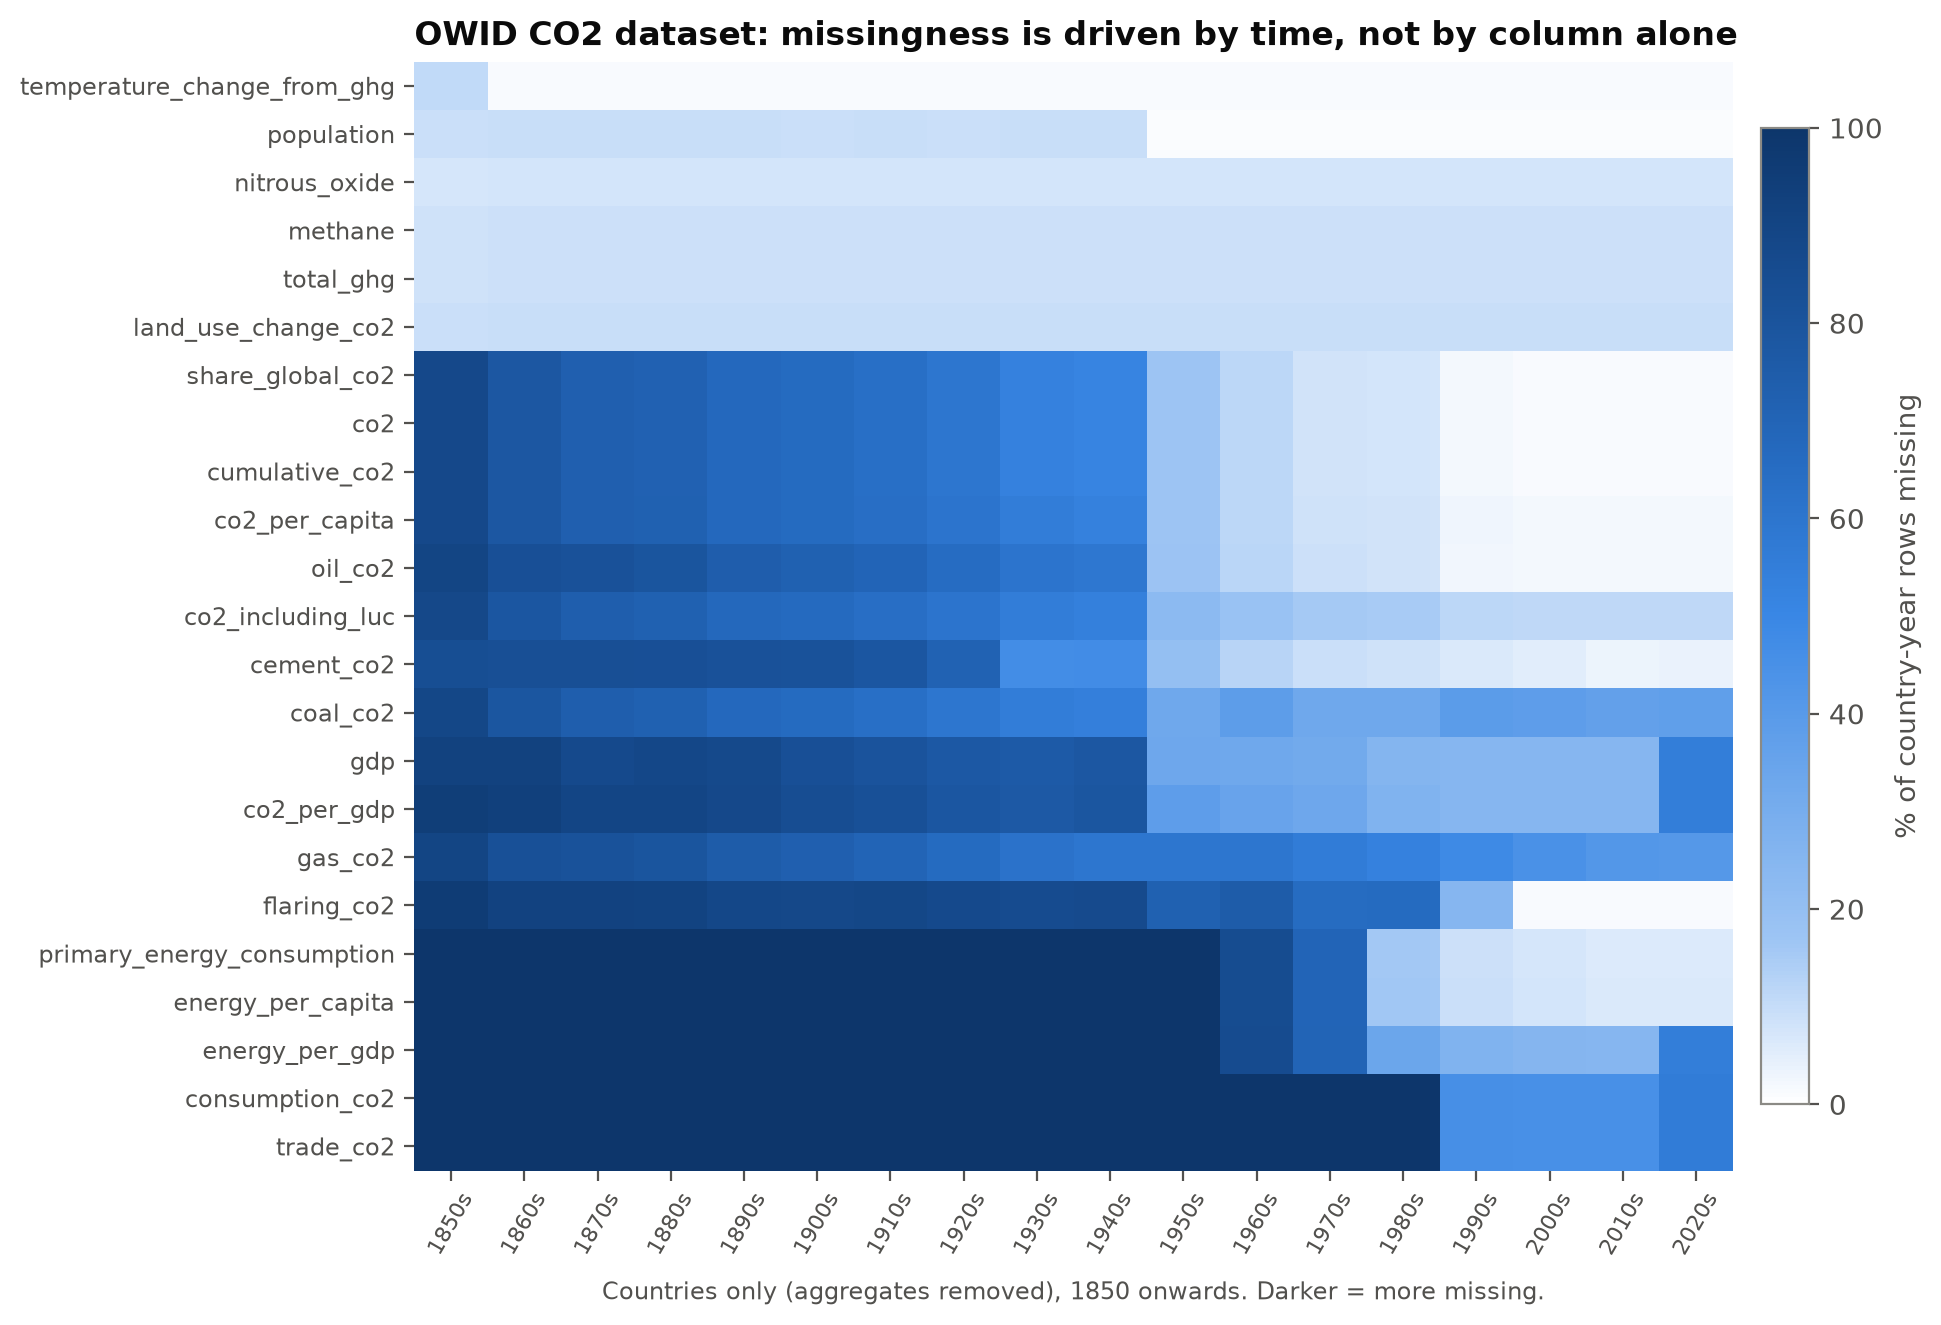

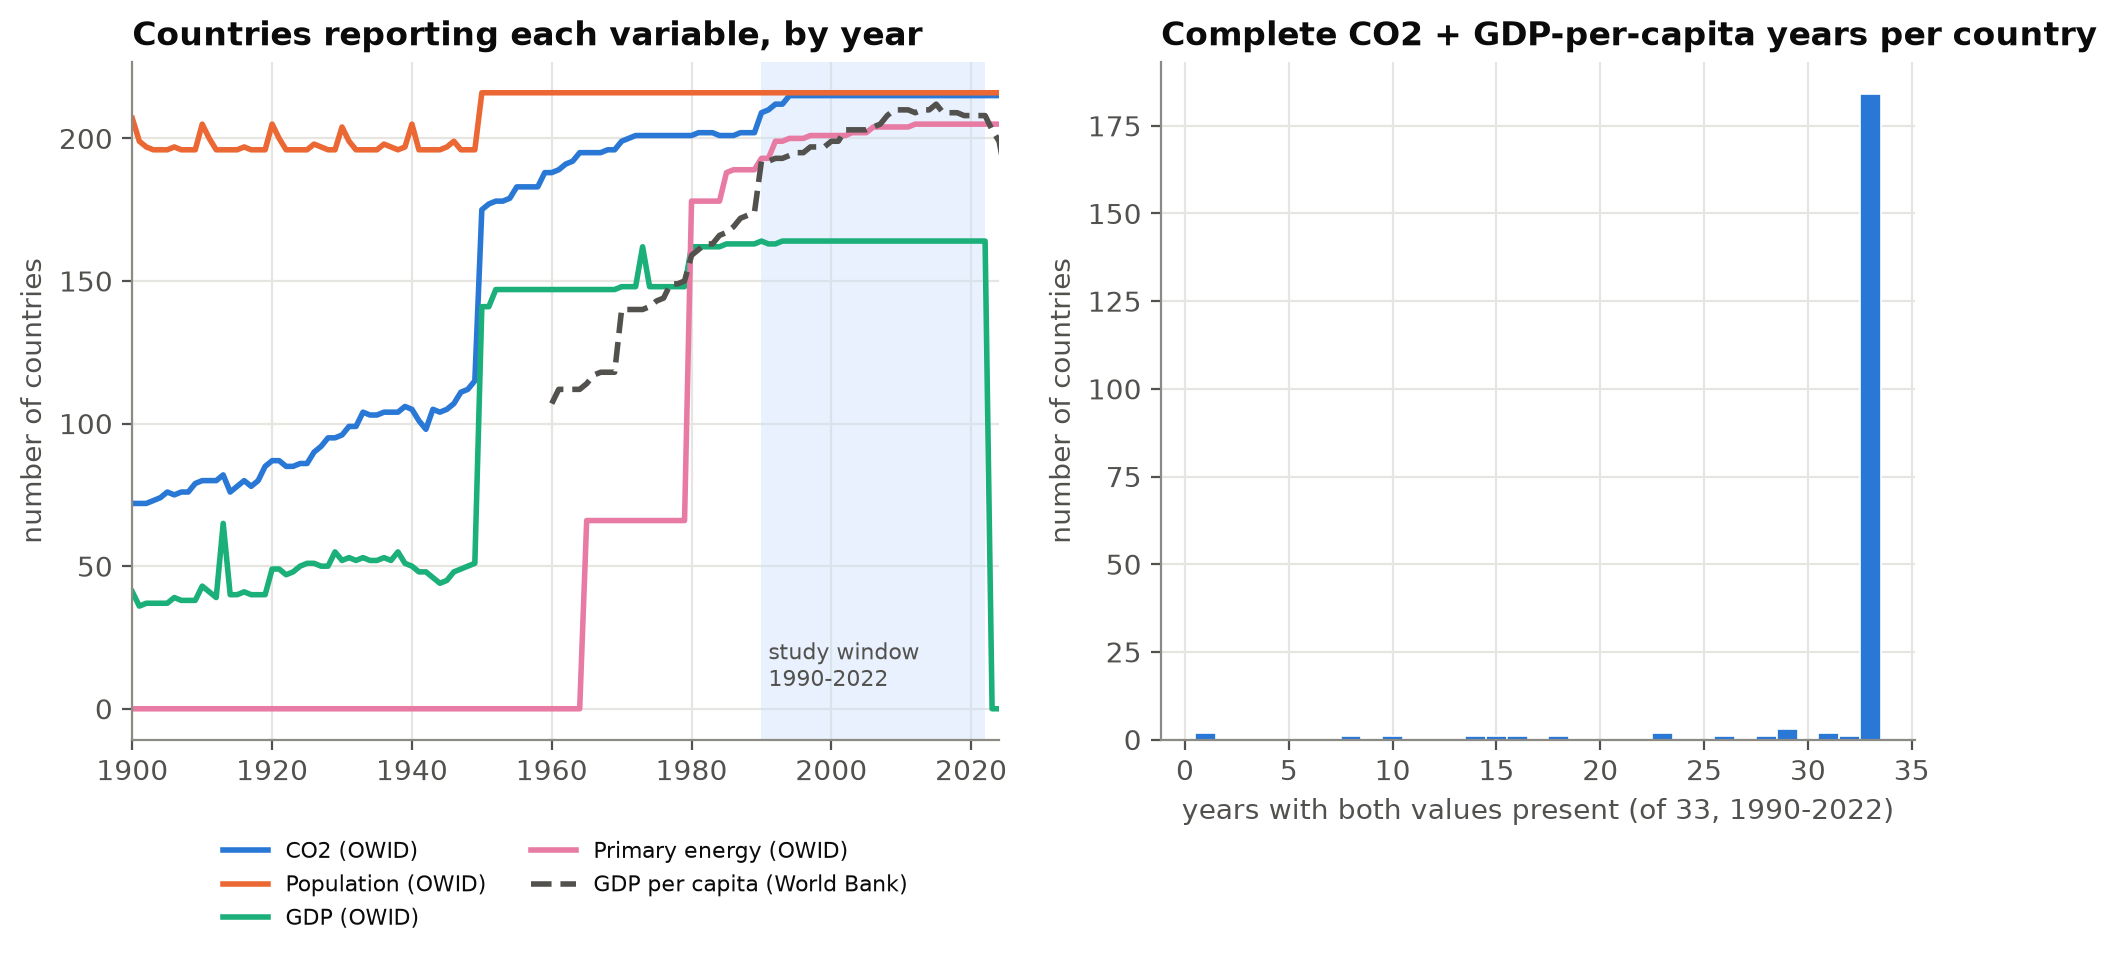

In [6]:
display(Image(str(ROOT / "figures/fig_profile_missing_heatmap.png"), width=760))
display(Image(str(ROOT / "figures/fig_profile_coverage_by_year.png"), width=980))

**Reading.** Missingness is mostly a function of *time*: CO2 is almost complete after 1990 but sparse before 1950, and OWID's own GDP column stops at 2022 and covers only 164 countries. That is why the study window is 1990-2022 and why GDP comes from the World Bank instead.

## 3. World Bank indicators

In [7]:
wbl = pd.read_csv(ROOT / "data/raw/worldbank_indicators_long.csv", keep_default_na=False, na_values=[""])
print("long table shape:", wbl.shape, "| API last updated:", wbl.source_last_updated.unique())
wmt = pd.read_csv(ROOT / "data/processed/profiling/worldbank_missing_by_indicator.csv", index_col=0)
wmt.assign(pct_missing_in_window=pd.Series(w["window_pct_missing_by_indicator"]))

long table shape: (87780, 7) | API last updated: <StringArray>
['2026-10-08']
Length: 1, dtype: str


,dtype,n_missing,pct_missing,n_unique,pct_missing_in_window
gdp_per_capita_ppp_const2021intl,float64,7345,51.28,6977,10.63
industry_value_added_pct_gdp,float64,5267,36.78,9015,15.63
gdp_per_capita_const2015usd,float64,2789,19.47,11533,6.41
population_wb,float64,30,0.21,14254,0.00
urban_pop_pct,float64,0,0.00,13684,0.00


**Reading.** The API returns aggregates (income groups, regions) in the same table as countries, and the five income-group rows have no ISO3 code at all. Excluding rows whose region is `Aggregates` leaves 217 countries. GDP per capita is 6.4% missing inside the study window, which is far better than OWID's 24.8%.

## 4. Joining the two sources

In [8]:
print(f"ISO3 codes in both: {j['iso3_matched']} | OWID only: {j['owid_unmatched_n']} | World Bank only: {j['wb_unmatched_n']}")
print(f"Exact country-name matches: {j['name_matched']}  (so a name join would silently drop {j['iso3_matched'] - j['name_matched']} countries)")
a = pd.read_csv(ROOT / "data/processed/profiling/key_match_owid_not_in_worldbank.csv")
b = pd.read_csv(ROOT / "data/processed/profiling/key_match_worldbank_not_in_owid.csv")
display(pd.concat([a.rename(columns={"country": "OWID-only entity"}).reset_index(drop=True),
                   b.rename(columns={"country_name": "World Bank-only entity"}).reset_index(drop=True)], axis=1))
mm = pd.read_csv(ROOT / "data/processed/profiling/key_match_name_mismatches_for_matched_iso.csv")
mm.head(10)

ISO3 codes in both: 206 | OWID only: 12 | World Bank only: 11
Exact country-name matches: 177  (so a name join would silently drop 29 countries)


,OWID-only entity,iso_code,iso3,World Bank-only entity
0,Anguilla,AIA,ASM,American Samoa
1,Antarctica,ATA,CYM,Cayman Islands
2,Bonaire Sint Eustatius and Saba,BES,CHI,Channel Islands
3,Christmas Island,CXR,GIB,Gibraltar
4,Cook Islands,COK,GUM,Guam
5,Montserrat,MSR,IMN,Isle of Man
6,Niue,NIU,XKX,Kosovo
7,Saint Helena,SHN,MNP,Northern Mariana Islands
8,Saint Pierre and Miquelon,SPM,PRI,Puerto Rico (US)
9,Taiwan,TWN,MAF,St. Martin (French part)


,iso_code,country,country_name
0,BHS,Bahamas,"Bahamas, The"
1,BRN,Brunei,Brunei Darussalam
2,COD,Democratic Republic of Congo,"Congo, Dem. Rep."
3,COG,Congo,"Congo, Rep."
4,CPV,Cape Verde,Cabo Verde
5,EGY,Egypt,"Egypt, Arab Rep."
6,FSM,Micronesia (country),"Micronesia, Fed. Sts."
7,GMB,Gambia,"Gambia, The"
8,HKG,Hong Kong,"Hong Kong SAR, China"
9,IRN,Iran,"Iran, Islamic Rep."


**Reading.** ISO3 is the correct join key. Name matching fails for 29 countries that *are* present in both sources (`Egypt` vs `Egypt, Arab Rep.`, `Cape Verde` vs `Cabo Verde`). A few entities are genuinely one-sided (Taiwan is not a World Bank economy; Kosovo has no ISO code in OWID).

In [9]:
summary = pd.Series({
    "joined country-year rows 1990-2022": j["joined_rows_window"],
    "countries in joined window": j["joined_countries_window"],
    "rows with both CO2/capita and GDP/capita": j["complete_pairs_co2pc_gdppc_window"],
    "share of joined rows complete (%)": j["pct_window_rows_complete_pairs"],
    "countries with all 33 years complete": j["countries_with_all_33_years_complete"],
    "countries complete in 2022": j["countries_complete_pair_2022"],
    "population: median OWID vs WB difference (%)": j["population_rel_diff_median_pct"],
    "population: 99th percentile difference (%)": j["population_rel_diff_p99_pct"],
    "countries with >5% population gap in some year": j["population_rel_diff_gt5pct_countries"],
}, name="value")
summary.to_frame()

,value
joined country-year rows 1990-2022,"6,798.00"
countries in joined window,206.00
rows with both CO2/capita and GDP/capita,"6,436.00"
share of joined rows complete (%),94.70
countries with all 33 years complete,184.00
countries complete in 2022,197.00
population: median OWID vs WB difference (%),0.00
population: 99th percentile difference (%),8.85
countries with >5% population gap in some year,15.00


## 5. Distributions and outliers

2022 CO2 per capita: median 3.16 t; top 5: [{'country': 'Qatar', 'co2_per_capita': 37.89}, {'country': 'Brunei', 'co2_per_capita': 26.87}, {'country': 'Kuwait', 'co2_per_capita': 25.24}, {'country': 'Trinidad and Tobago', 'co2_per_capita': 25.06}, {'country': 'Bahrain', 'co2_per_capita': 24.67}]
skew raw: 2.53 | skew after log10: -0.6
IQR outliers raw: 14 of 213 | after log10: 2
World Bank GDP pc 2022 median: 6599.0 | skew raw: 3.25 | log10: -0.06
Preview (2022, n=197): log-log Pearson 0.853, Spearman 0.857, raw Pearson 0.508


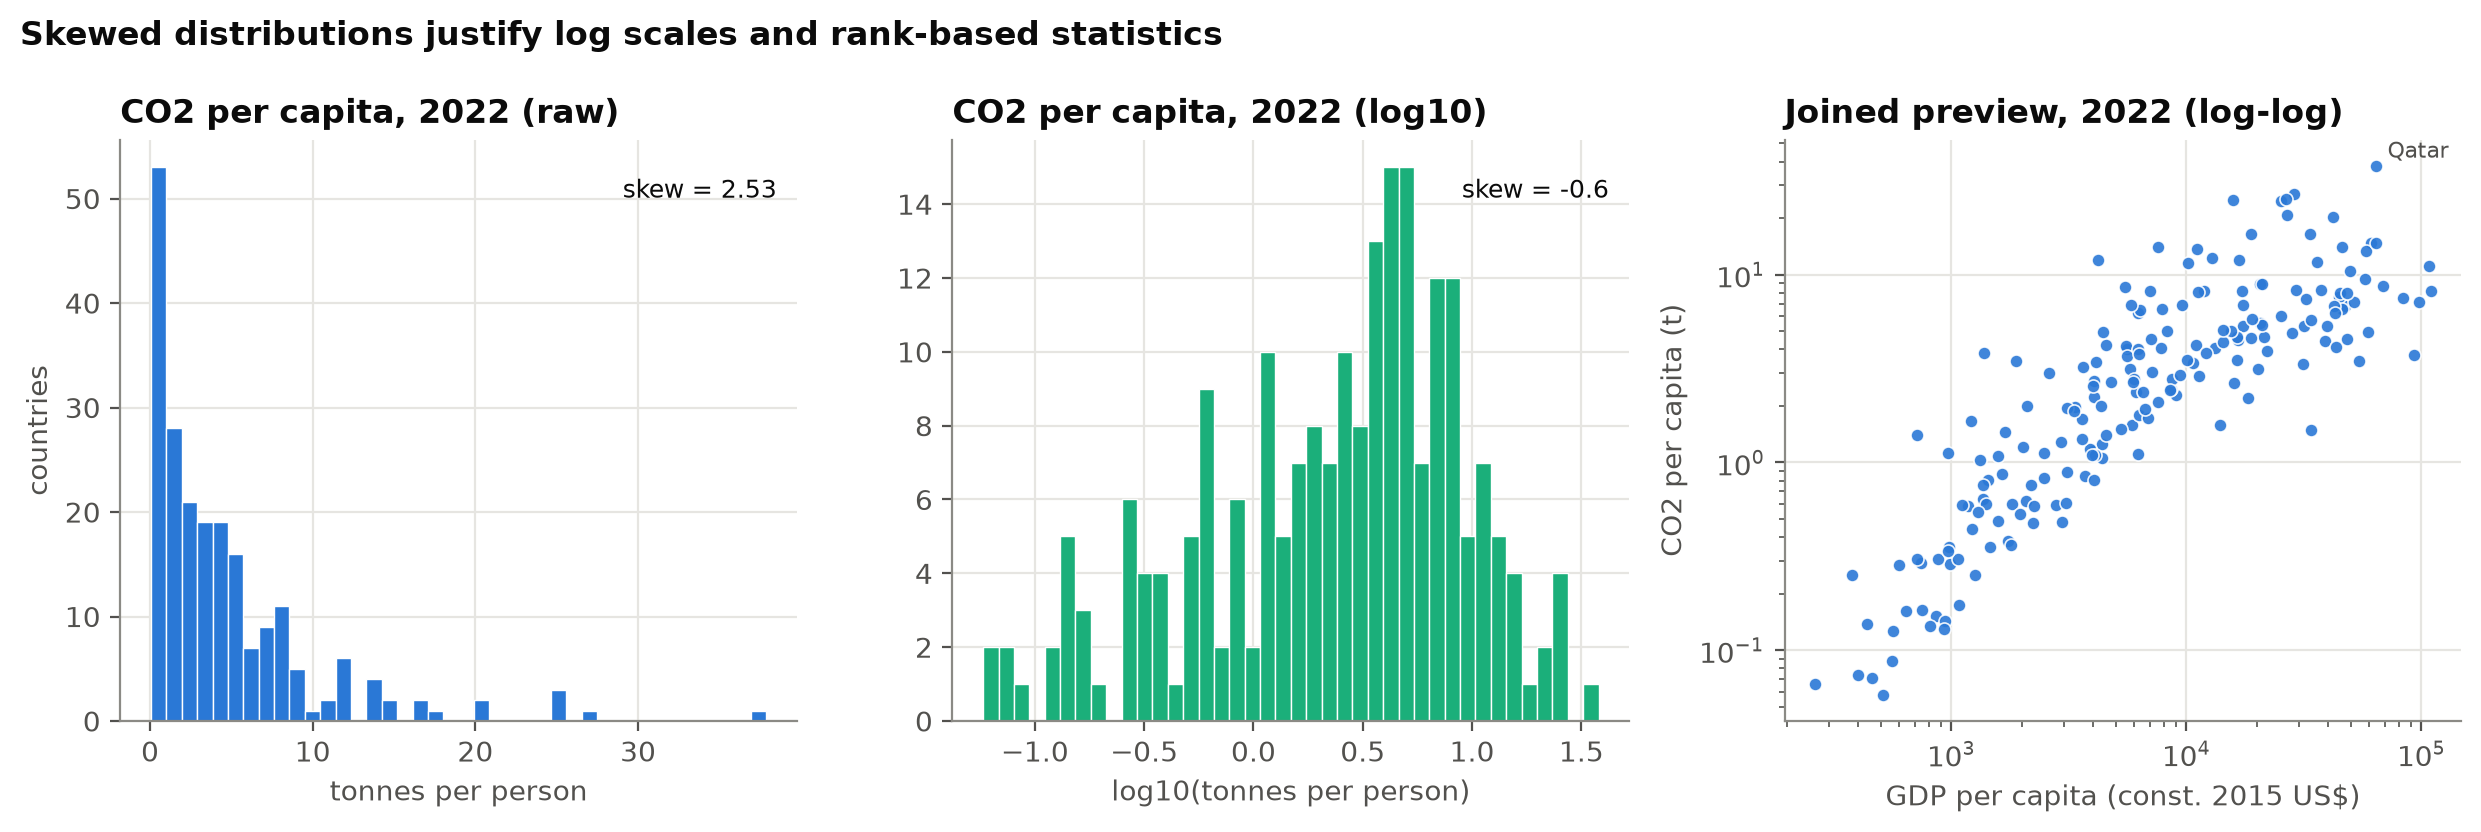

In [10]:
print("2022 CO2 per capita: median", o["co2_per_capita_2022_median"], "t; top 5:", o["top5_co2_per_capita_2022"])
print("skew raw:", o["skew_co2_pc_2022"], "| skew after log10:", o["skew_log_co2_pc_2022"])
print("IQR outliers raw:", o["outliers_co2_per_capita_2022"]["n_outliers"], "of", o["outliers_co2_per_capita_2022"]["n"],
      "| after log10:", o["outliers_co2_per_capita_2022_log"]["n_outliers"])
print("World Bank GDP pc 2022 median:", w["gdp_pc_2022_median"], "| skew raw:", w["skew_gdp_pc_2022"], "| log10:", w["skew_log_gdp_pc_2022"])
print("Preview (2022, n=%d): log-log Pearson %.3f, Spearman %.3f, raw Pearson %.3f" % (
    j["countries_complete_pair_2022"], j["preview_log_pearson_2022"], j["preview_spearman_2022"], j["preview_raw_pearson_2022"]))
display(Image(str(ROOT / "figures/fig_profile_distributions.png"), width=980))

**Reading.** Raw per-capita CO2 is strongly right-skewed (skew 2.53) and a log10 transform cuts the skew from 2.53 to -0.60 and reduces the IQR-flagged outliers from 14 to 2; the high values are small, oil-rich economies (Qatar, Brunei, Kuwait), which are real, not errors. The correlation preview is only a smoke test that the join produces sensible pairs; the real analysis happens in the full project.

## 6. What the profiling means for the cleaning plan

1. Keep the 1990-2022 window; use World Bank GDP per capita, with OWID GDP only as a cross-check.
2. Split aggregates from countries using the missing `iso_code` (OWID) and the `Aggregates` region (World Bank).
3. Join on ISO3 and year, never on names; patch Kosovo and list the one-sided entities.
4. Never impute CO2 or GDP per capita; allow short interpolation only for secondary covariates.
5. Keep high per-capita emitters and analyse on log scales with rank-based statistics.